# Results visualization

Load the exported results under `results/` and visualize model performance, robustness, frontend shifts, prediction concentration, confusion matrices, and training history.

This notebook is read-only with respect to the result files: it loads existing CSV/JSON artifacts and creates charts in the notebook output.

In [9]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
display = print

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "results").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "results").is_dir():
    raise FileNotFoundError("Could not find a results/ directory from the notebook location.")

RESULTS = ROOT / "results"
VALIDATION = RESULTS / "results" / "exploratory_validation"
if not VALIDATION.is_dir():
    VALIDATION = RESULTS / "exploratory_validation"
if not VALIDATION.is_dir():
    raise FileNotFoundError(f"Could not find exploratory validation results under {RESULTS}.")

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
print(f"Repository: {ROOT}")
print(f"Validation results: {VALIDATION}")

Repository: /Users/vnpq/_MLDM/Research method/Research-Methodology
Validation results: /Users/vnpq/_MLDM/Research method/Research-Methodology/results/results/exploratory_validation


## Load tabular results

In [10]:
csv_files = sorted(VALIDATION.glob("*.csv"))
tables = {path.stem: pd.read_csv(path) for path in csv_files}
for name, table in tables.items():
    print(f"{name}: {table.shape[0]} rows x {table.shape[1]} columns")

metrics = tables["metrics_summary"].copy()
metrics["target_snr"] = pd.to_numeric(metrics["target_snr"], errors="coerce")
metrics["condition"] = metrics["condition"].astype(str)
display(metrics)

class_split_counts: 36 rows x 4 columns
clip_measurements: 901 rows x 3 columns
confusion_clean: 36 rows x 37 columns
confusion_fgsm_20: 36 rows x 37 columns
confusion_gaussian_20_pooled: 36 rows x 37 columns
frontend_shift: 29 rows x 6 columns
metrics_per_replicate: 29 rows x 16 columns
metrics_summary: 15 rows x 18 columns
paired_effects: 7 rows x 10 columns
prediction_concentration: 29 rows x 10 columns
prediction_distribution: 1044 rows x 6 columns
predictions: 5220 rows x 19 columns
   condition  target_snr  replicates    n  master_seed  accuracy  \
0      clean         NaN           1  180           26  0.961111   
1       fgsm        10.0           1  180           26  0.033333   
2       fgsm        20.0           1  180           26  0.033333   
3       fgsm        30.0           1  180           26  0.044444   
4       fgsm        35.0           1  180           26  0.050000   
5       fgsm        40.0           1  180           26  0.094444   
6       fgsm        50.0       

## Accuracy, macro-F1, and attack success rate

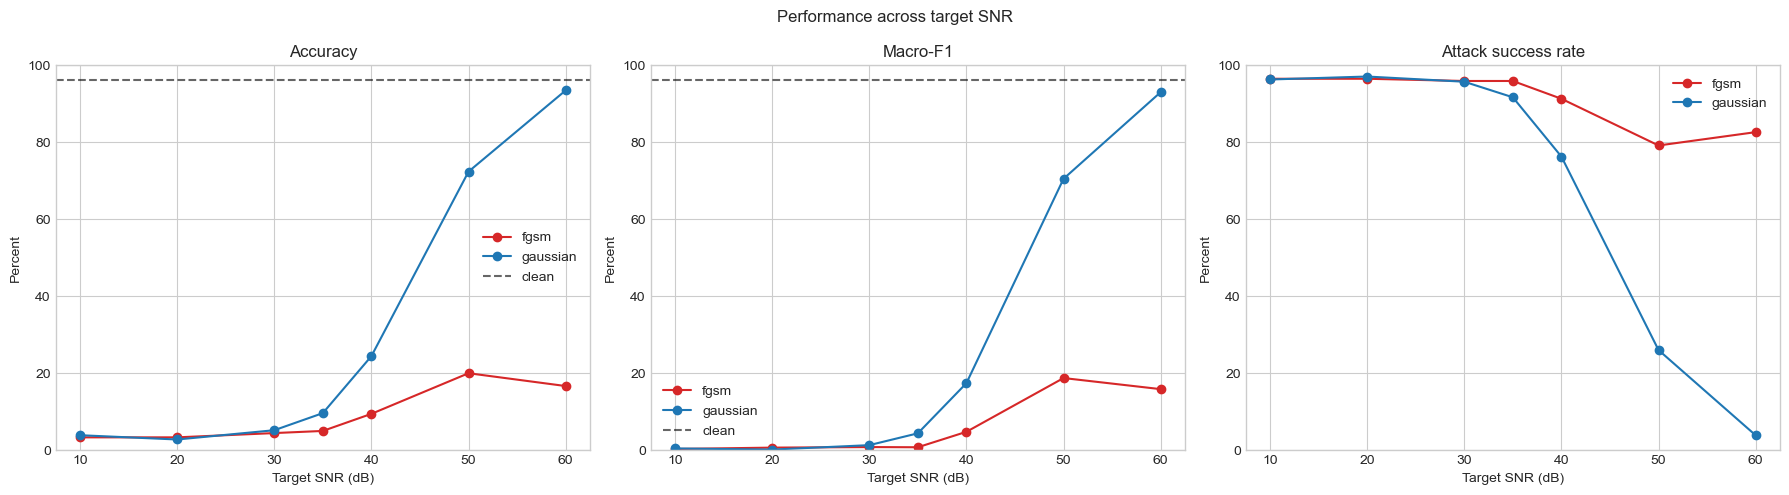

In [11]:
plot_metrics = metrics.dropna(subset=["target_snr"]).copy()
colors = {"gaussian": "#1f77b4", "fgsm": "#d62728"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for condition, group in plot_metrics.groupby("condition"):
    group = group.sort_values("target_snr")
    color = colors.get(condition, "#333333")
    axes[0].plot(group["target_snr"], group["accuracy"] * 100, marker="o", label=condition, color=color)
    axes[1].plot(group["target_snr"], group["macro_f1"] * 100, marker="o", label=condition, color=color)
    axes[2].plot(group["target_snr"], group["asr"] * 100, marker="o", label=condition, color=color)
clean = metrics[metrics["condition"] == "clean"]
if not clean.empty:
    clean_acc = clean["accuracy"].iloc[0] * 100
    clean_f1 = clean["macro_f1"].iloc[0] * 100
    axes[0].axhline(clean_acc, color="black", linestyle="--", alpha=0.6, label="clean")
    axes[1].axhline(clean_f1, color="black", linestyle="--", alpha=0.6, label="clean")
for ax, title, ylabel in zip(axes, ["Accuracy", "Macro-F1", "Attack success rate"], ["Percent", "Percent", "Percent"]):
    ax.set(title=title, xlabel="Target SNR (dB)", ylabel=ylabel)
    ax.set_ylim(0, 100)
    ax.legend()
fig.suptitle("Performance across target SNR")
fig.tight_layout()
plt.show()

Error bars below show the replicate standard deviation where it is available.

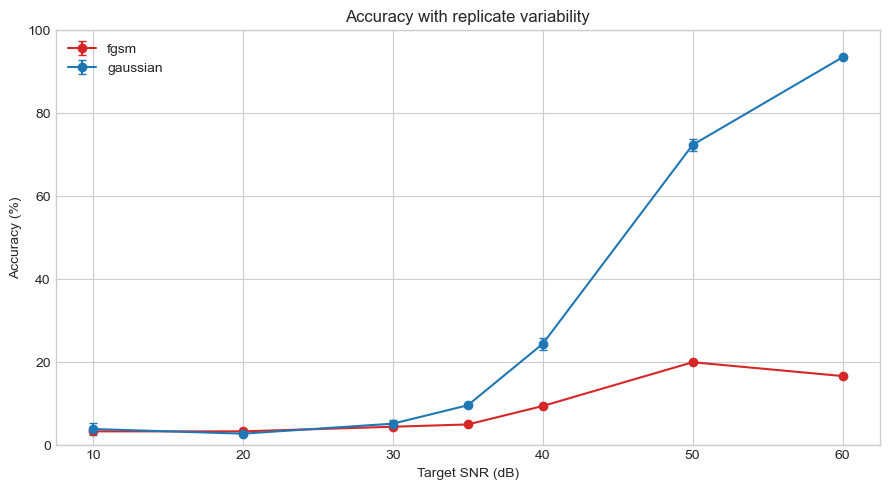

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
for condition, group in plot_metrics.groupby("condition"):
    group = group.sort_values("target_snr")
    ax.errorbar(group["target_snr"], group["accuracy"] * 100, yerr=group["accuracy_std"].fillna(0) * 100,
                marker="o", capsize=3, label=condition, color=colors.get(condition, "#333333"))
ax.set(title="Accuracy with replicate variability", xlabel="Target SNR (dB)", ylabel="Accuracy (%)", ylim=(0, 100))
ax.legend()
fig.tight_layout()
plt.show()

## Frontend feature shift

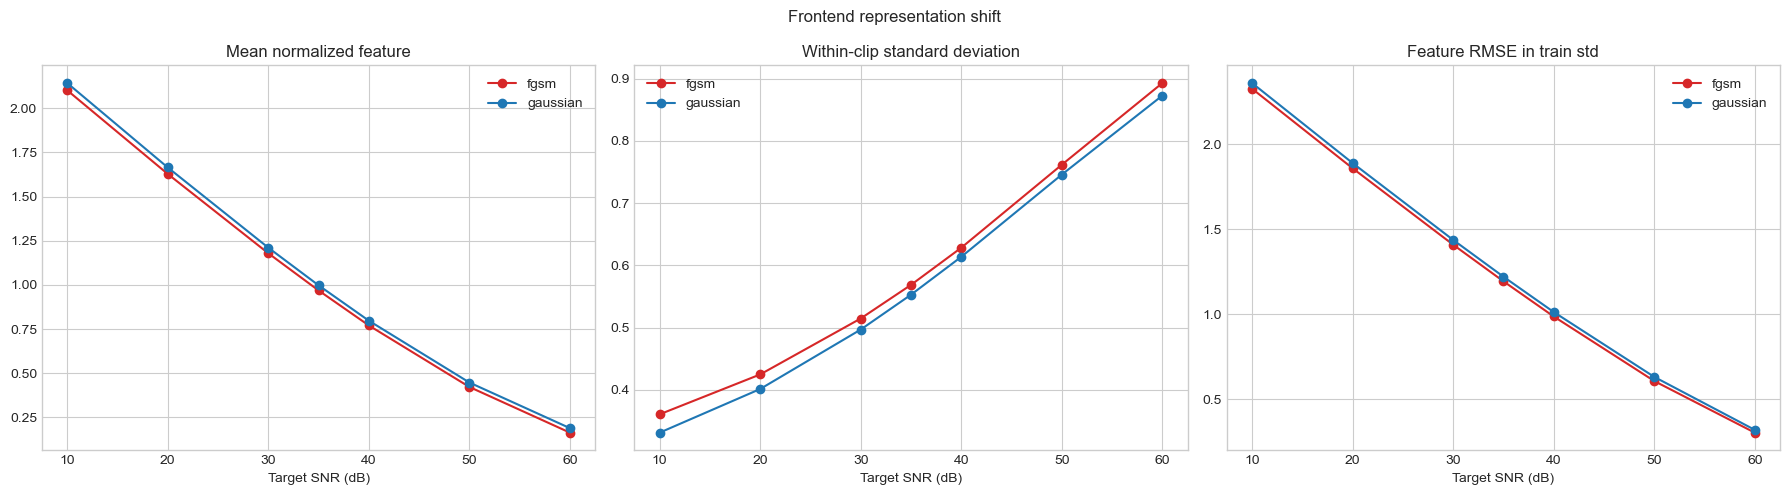

In [13]:
frontend = tables["frontend_shift"].copy()
frontend["target_snr"] = pd.to_numeric(frontend["target_snr"], errors="coerce")
frontend_plot = frontend.dropna(subset=["target_snr"])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for condition, group in frontend_plot.groupby("condition"):
    group = group.groupby("target_snr", as_index=False).mean(numeric_only=True).sort_values("target_snr")
    label = condition
    axes[0].plot(group["target_snr"], group["mean_normalized"], marker="o", label=label, color=colors.get(condition))
    axes[1].plot(group["target_snr"], group["mean_within_clip_std"], marker="o", label=label, color=colors.get(condition))
    axes[2].plot(group["target_snr"], group["feature_rmse_in_train_std"], marker="o", label=label, color=colors.get(condition))
titles = ["Mean normalized feature", "Within-clip standard deviation", "Feature RMSE in train std"]
for ax, title in zip(axes, titles):
    ax.set(title=title, xlabel="Target SNR (dB)")
    ax.legend()
fig.suptitle("Frontend representation shift")
fig.tight_layout()
plt.show()

## Prediction concentration and entropy

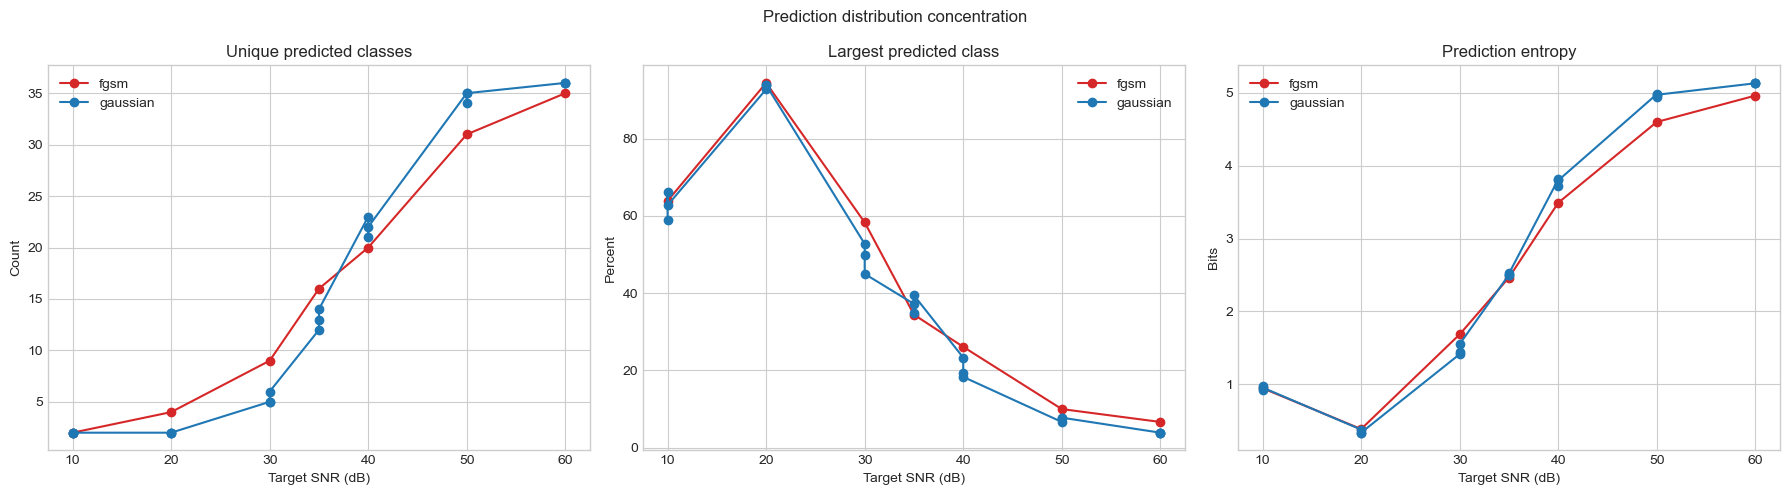

In [14]:
concentration = tables["prediction_concentration"].copy()
concentration["target_snr"] = pd.to_numeric(concentration["target_snr"], errors="coerce")
concentration_plot = concentration.dropna(subset=["target_snr"])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for condition, group in concentration_plot.groupby("condition"):
    group = group.sort_values("target_snr")
    color = colors.get(condition, "#333333")
    axes[0].plot(group["target_snr"], group["unique_predicted_classes"], marker="o", label=condition, color=color)
    axes[1].plot(group["target_snr"], group["largest_class_fraction"] * 100, marker="o", label=condition, color=color)
    axes[2].plot(group["target_snr"], group["predicted_label_entropy_bits"], marker="o", label=condition, color=color)
for ax, title, ylabel in zip(axes, ["Unique predicted classes", "Largest predicted class", "Prediction entropy"], ["Count", "Percent", "Bits"]):
    ax.set(title=title, xlabel="Target SNR (dB)", ylabel=ylabel)
    ax.legend()
fig.suptitle("Prediction distribution concentration")
fig.tight_layout()
plt.show()

## Confusion matrices

/var/folders/lq/t5nztjcd12g_vsc0wjr70y240000gn/T/ipykernel_62611/889348757.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


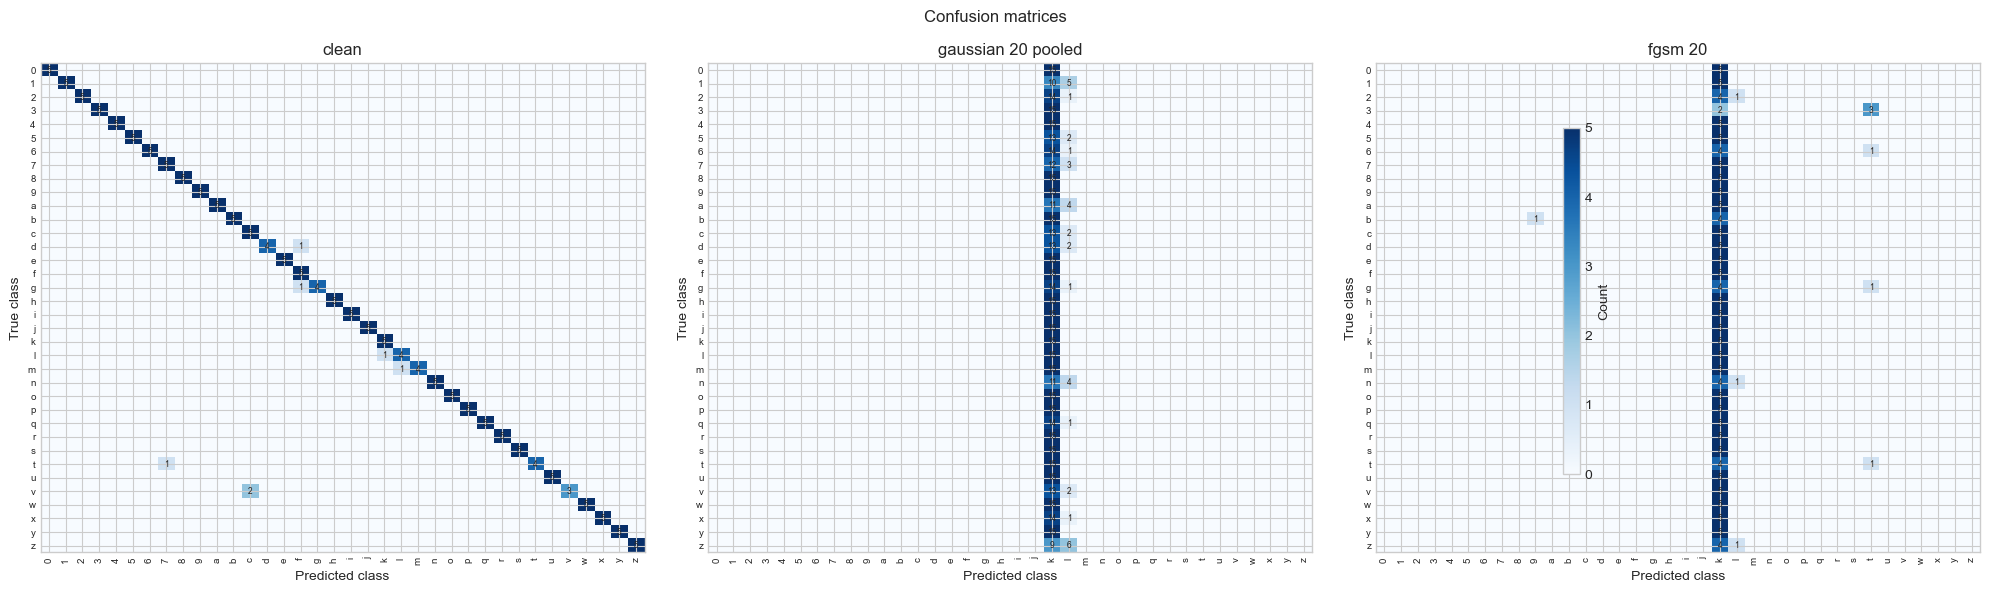

In [15]:
confusion_names = ["confusion_clean", "confusion_gaussian_20_pooled", "confusion_fgsm_20"]
fig, axes = plt.subplots(1, len(confusion_names), figsize=(20, 6))
for ax, name in zip(axes, confusion_names):
    matrix = pd.read_csv(VALIDATION / f"{name}.csv", index_col=0)
    image = ax.imshow(matrix.to_numpy(), cmap="Blues", aspect="auto")
    ax.set(title=name.replace("confusion_", "").replace("_", " "), xlabel="Predicted class", ylabel="True class")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(matrix.index)), matrix.index, fontsize=7)
    for row in range(len(matrix.index)):
        for col in range(len(matrix.columns)):
            value = matrix.iat[row, col]
            if value:
                ax.text(col, row, int(value), ha="center", va="center", fontsize=6)
fig.colorbar(image, ax=axes, shrink=0.75, label="Count")
fig.suptitle("Confusion matrices")
fig.tight_layout()
plt.show()

## Paired effects and training history

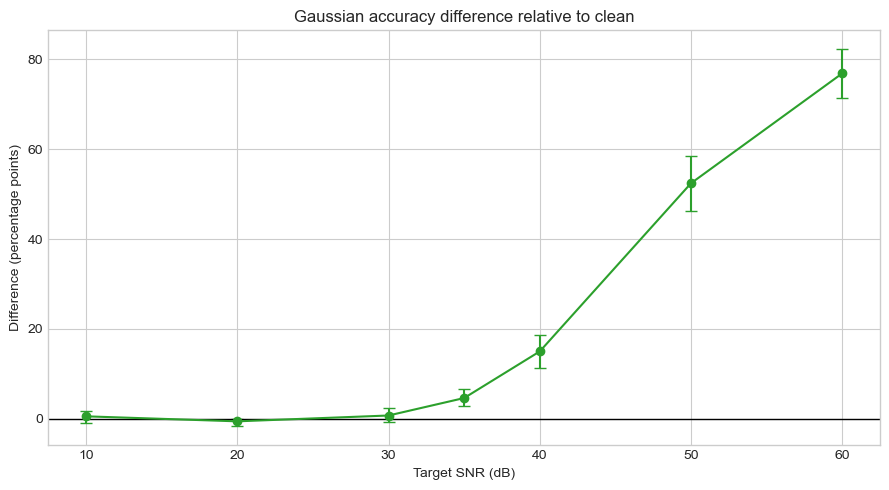

   epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1  \
0      1    3.926818        0.022181  3.741664      0.027778      0.001502   
1      2    3.792251        0.018484  3.730827      0.027778      0.001502   
2      3    3.799971        0.027726  3.721781      0.027778      0.001502   
3      4    3.738209        0.018484  3.696597      0.027778      0.001502   
4      5    3.696037        0.020333  3.895895      0.033333      0.003117   

   learning_rate   seconds  
0       0.000500  3.966276  
1       0.000500  1.642369  
2       0.000499  1.593199  
3       0.000499  1.878474  
4       0.000498  1.637913  


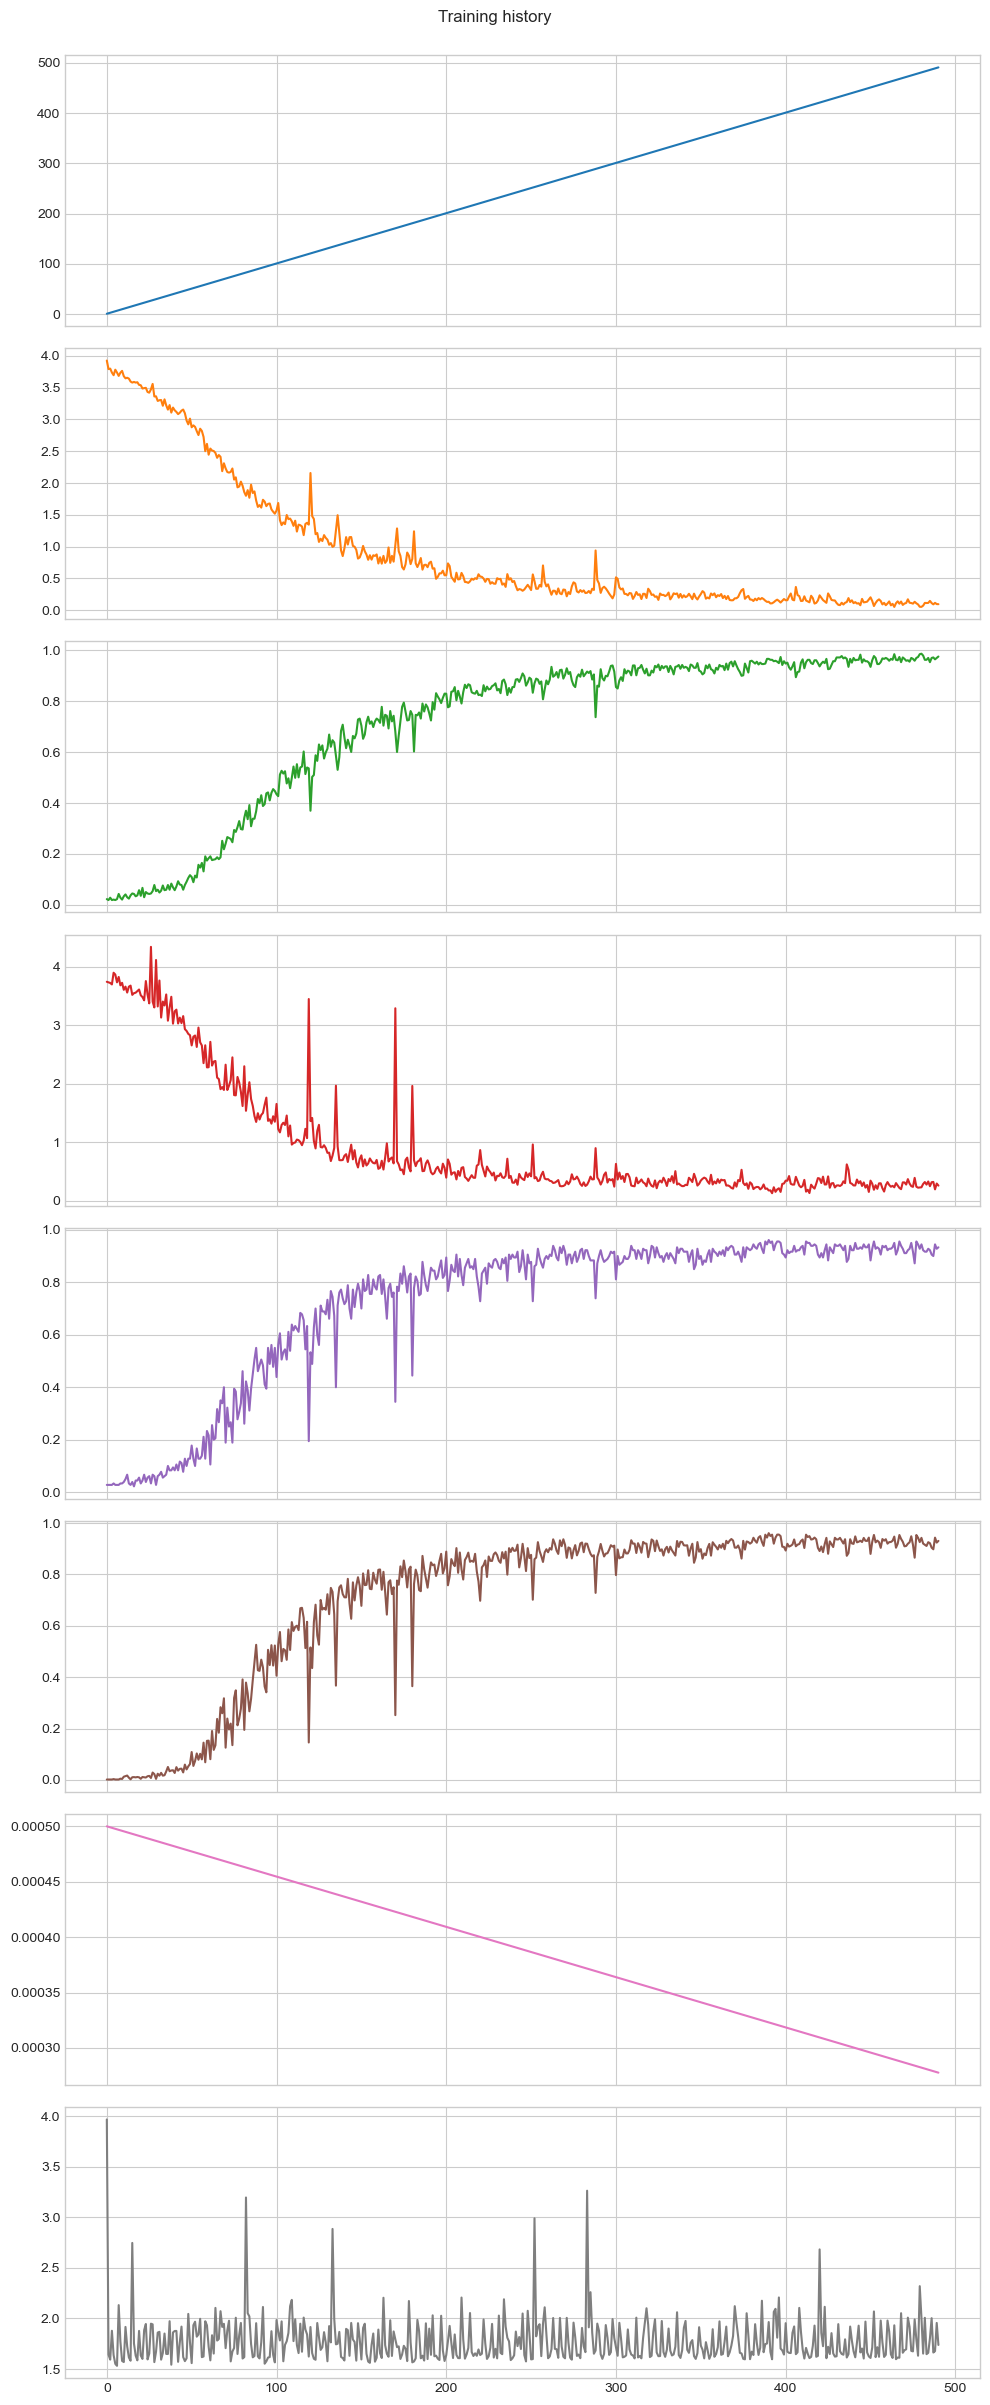

In [16]:
paired = tables["paired_effects"].sort_values("target_snr")
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(paired["target_snr"], paired["difference_pp"],
            yerr=[paired["difference_pp"] - paired["ci_low_pp"], paired["ci_high_pp"] - paired["difference_pp"]],
            fmt="o-", capsize=4, color="#2ca02c")
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Gaussian accuracy difference relative to clean", xlabel="Target SNR (dB)", ylabel="Difference (percentage points)")
fig.tight_layout()
plt.show()

history_path = RESULTS / "training" / "history.csv"
if history_path.is_file():
    history = pd.read_csv(history_path)
    display(history.head())
    numeric_history = history.select_dtypes(include="number")
    ax = numeric_history.plot(subplots=True, figsize=(10, 3 * len(numeric_history.columns)), layout=(len(numeric_history.columns), 1), legend=False)
    plt.suptitle("Training history", y=1.0)
    plt.tight_layout()
    plt.show()
else:
    print(f"Training history not found at {history_path}; skipping training chart.")

## Result metadata

The JSON metadata files are loaded here for quick provenance checks.

In [17]:
metadata_files = ["analysis_metadata.json", "evaluation_metadata.json", "completion.json"]
metadata = {}
for filename in metadata_files:
    path = VALIDATION / filename
    if path.is_file():
        with path.open(encoding="utf-8") as handle:
            metadata[filename] = json.load(handle)
        print(f"Loaded {filename}")
display(pd.DataFrame({"file": list(metadata), "top_level_keys": [list(value) for value in metadata.values()]}))

Loaded analysis_metadata.json
Loaded evaluation_metadata.json
Loaded completion.json
                       file                                     top_level_keys
0    analysis_metadata.json  [partition, analysis_role, bootstrap_repetitio...
1  evaluation_metadata.json  [partition, analysis_role, checkpoint_sha256, ...
2           completion.json  [complete, finished_utc, checkpoint_sha256, ou...
